
# FlotIQ | Machine Learning

## 03. Predicción del precio de la electricidad

### Objetivo
Entrenar y comparar diferentes modelos de Machine Learning
para predecir el precio mayorista de OMIE con hasta
48 horas de antelación.

### Modelos
- Ridge Regression
- Random Forest
- HistGradientBoosting
- XGBoost

### Evaluación
- Validación temporal
- MAE y RMSE
- Comparación con el baseline semanal
- Análisis de errores en horas caras y baratas

**Mejor baseline actual: 27,66 €/MWh de MAE.**


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Localizar la raíz del proyecto
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "omie_ml_hourly.parquet"
)

df = pd.read_parquet(DATA_PATH)

df["datetime_utc"] = pd.to_datetime(
    df["datetime_utc"],
    utc=True
)

df = df.sort_values("datetime_utc").reset_index(drop=True)

print("Dataset cargado correctamente")
print("Filas:", len(df))
print("Columnas:", len(df.columns))


Dataset cargado correctamente
Filas: 32640
Columnas: 15


In [2]:
# VARIABLES PREDICTORAS
# ==========================================

FEATURES = [
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "day_of_week",
    "is_weekend",
    "price_lag_72h",
    "price_lag_168h",
]

TARGET = "price_eur_mwh"

# Reservar últimos 90 días como test final
test_start = (
    df["datetime_utc"].max()
    - pd.Timedelta(days=90)
    + pd.Timedelta(hours=1)
)

train_val = df[
    df["datetime_utc"] < test_start
].copy()

test = df[
    df["datetime_utc"] >= test_start
].copy()

# Últimos 60 días del periodo anterior
# como validación
val_start = (
    train_val["datetime_utc"].max()
    - pd.Timedelta(days=60)
    + pd.Timedelta(hours=1)
)

train = train_val[
    train_val["datetime_utc"] < val_start
].copy()

val = train_val[
    train_val["datetime_utc"] >= val_start
].copy()

X_train = train[FEATURES]
y_train = train[TARGET]

X_val = val[FEATURES]
y_val = val[TARGET]

print("Entrenamiento:", len(train), "filas")
print("Validación:", len(val), "filas")
print("Test reservado:", len(test), "filas")

assert train["datetime_utc"].max() < val["datetime_utc"].min()
assert val["datetime_utc"].max() < test["datetime_utc"].min()

print("\nDivisión temporal correcta")


Entrenamiento: 29040 filas
Validación: 1440 filas
Test reservado: 2160 filas

División temporal correcta


In [3]:
# FLOTIQ | RIDGE REGRESSION
# ==========================================

alphas = [0.1, 1, 10, 100, 1000]

resultados = []
modelos = {}

for alpha in alphas:

    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_val)

    mae = mean_absolute_error(
        y_val, predicciones
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, predicciones)
    )

    resultados.append({
        "alpha": alpha,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

    modelos[alpha] = modelo

resultados_ridge = pd.DataFrame(resultados)

display(
    resultados_ridge.sort_values("MAE")
)

# Mejor configuración según validación
mejor_alpha = resultados_ridge.loc[
    resultados_ridge["MAE"].idxmin(),
    "alpha"
]

mejor_ridge = modelos[mejor_alpha]

# Baseline semanal en el mismo periodo
mae_baseline_val = mean_absolute_error(
    y_val,
    val["price_lag_168h"]
)

print(f"\nMejor alpha: {mejor_alpha}")
print(f"MAE baseline semanal (validación): {mae_baseline_val:.2f} €/MWh")
print(
    "MAE mejor Ridge (validación): "
    f"{resultados_ridge['MAE'].min():.2f} €/MWh"
)


,alpha,MAE,RMSE
0,0.1,21.35,26.46
1,1.0,21.36,26.46
2,10.0,21.36,26.46
3,100.0,21.38,26.47
4,1000.0,21.59,26.56



Mejor alpha: 0.1
MAE baseline semanal (validación): 21.37 €/MWh
MAE mejor Ridge (validación): 21.35 €/MWh


In [4]:
# FLOTIQ | RANDOM FOREST
# ==========================================

from sklearn.ensemble import RandomForestRegressor

configuraciones = [
    {"max_depth": 8, "min_samples_leaf": 10},
    {"max_depth": 14, "min_samples_leaf": 5},
]

resultados_rf = []
modelos_rf = {}

for config in configuraciones:

    modelo = RandomForestRegressor(
        n_estimators=150,
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        random_state=42,
        n_jobs=-1,
    )

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_val)

    mae = mean_absolute_error(y_val, predicciones)

    rmse = np.sqrt(
        mean_squared_error(y_val, predicciones)
    )

    resultados_rf.append({
        "max_depth": config["max_depth"],
        "min_samples_leaf": config["min_samples_leaf"],
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
    })

    modelos_rf[config["max_depth"]] = modelo

resultados_rf_df = pd.DataFrame(resultados_rf)

display(resultados_rf_df.sort_values("MAE"))

# Seleccionar mejor configuración
mejor_fila = resultados_rf_df.loc[
    resultados_rf_df["MAE"].idxmin()
]

mejor_rf = modelos_rf[int(mejor_fila["max_depth"])]

print("\nCOMPARACIÓN DE MODELOS")
print("-" * 40)
print(f"Baseline semanal: {mae_baseline_val:.2f} €/MWh")
print(f"Ridge Regression: {resultados_ridge['MAE'].min():.2f} €/MWh")
print(f"Random Forest:    {mejor_fila['MAE']:.2f} €/MWh")


,max_depth,min_samples_leaf,MAE,RMSE
0,8,10,20.33,26.57
1,14,5,20.58,27.27



COMPARACIÓN DE MODELOS
----------------------------------------
Baseline semanal: 21.37 €/MWh
Ridge Regression: 21.35 €/MWh
Random Forest:    20.33 €/MWh


In [5]:
# FLOTIQ | HIST GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import HistGradientBoostingRegressor

configuraciones_hgb = [
    {"learning_rate": 0.05, "max_iter": 200},
    {"learning_rate": 0.10, "max_iter": 200},
    {"learning_rate": 0.05, "max_iter": 400},
]

resultados_hgb = []
modelos_hgb = {}

for i, config in enumerate(configuraciones_hgb):

    modelo = HistGradientBoostingRegressor(
        learning_rate=config["learning_rate"],
        max_iter=config["max_iter"],
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_val)

    mae = mean_absolute_error(
        y_val, predicciones
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, predicciones)
    )

    resultados_hgb.append({
        "learning_rate": config["learning_rate"],
        "max_iter": config["max_iter"],
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
    })

    modelos_hgb[i] = modelo

resultados_hgb_df = pd.DataFrame(resultados_hgb)

display(
    resultados_hgb_df.sort_values("MAE")
)

mejor_indice = resultados_hgb_df["MAE"].idxmin()
mejor_hgb = modelos_hgb[mejor_indice]

print("\nCOMPARACIÓN DE MODELOS")
print("-" * 45)
print(f"Baseline:      {mae_baseline_val:.2f} €/MWh")
print(f"Ridge:         {resultados_ridge['MAE'].min():.2f} €/MWh")
print(f"Random Forest: {resultados_rf_df['MAE'].min():.2f} €/MWh")
print(f"HistBoosting:  {resultados_hgb_df['MAE'].min():.2f} €/MWh")


,learning_rate,max_iter,MAE,RMSE
0,0.05,200,19.82,26.11
2,0.05,400,20.15,26.73
1,0.10,200,20.29,27.02



COMPARACIÓN DE MODELOS
---------------------------------------------
Baseline:      21.37 €/MWh
Ridge:         21.35 €/MWh
Random Forest: 20.33 €/MWh
HistBoosting:  19.82 €/MWh


In [6]:
# FLOTIQ | XGBOOST
# ==========================================

from xgboost import XGBRegressor

configuraciones_xgb = [
    {
        "max_depth": 3,
        "learning_rate": 0.05,
        "n_estimators": 300
    },
    {
        "max_depth": 5,
        "learning_rate": 0.05,
        "n_estimators": 300
    },
    {
        "max_depth": 3,
        "learning_rate": 0.03,
        "n_estimators": 500
    },
]

resultados_xgb = []
modelos_xgb = {}

for i, config in enumerate(configuraciones_xgb):

    modelo = XGBRegressor(
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        n_estimators=config["n_estimators"],
        objective="reg:squarederror",
        subsample=0.8,
        colsample_bytree=0.9,
        reg_lambda=5.0,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    )

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_val)

    mae = mean_absolute_error(
        y_val,
        predicciones
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, predicciones)
    )

    resultados_xgb.append({
        "max_depth": config["max_depth"],
        "learning_rate": config["learning_rate"],
        "n_estimators": config["n_estimators"],
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

    modelos_xgb[i] = modelo

resultados_xgb_df = pd.DataFrame(resultados_xgb)

display(
    resultados_xgb_df.sort_values("MAE")
)

# Mejor configuración
mejor_indice_xgb = resultados_xgb_df["MAE"].idxmin()

mejor_xgb = modelos_xgb[mejor_indice_xgb]

# Comparación global
comparacion = pd.DataFrame([
    {"Modelo": "Baseline semanal", "MAE": mae_baseline_val},
    {"Modelo": "Ridge", "MAE": resultados_ridge["MAE"].min()},
    {"Modelo": "Random Forest", "MAE": resultados_rf_df["MAE"].min()},
    {"Modelo": "HistGradientBoosting", "MAE": resultados_hgb_df["MAE"].min()},
    {"Modelo": "XGBoost", "MAE": resultados_xgb_df["MAE"].min()}
])

print("\nRANKING FLOTIQ")
display(
    comparacion.sort_values("MAE").round(2)
)


,max_depth,learning_rate,n_estimators,MAE,RMSE
2,3,0.03,500,20.25,26.01
0,3,0.05,300,20.26,25.95
1,5,0.05,300,20.54,26.99



RANKING FLOTIQ


,Modelo,MAE
3,HistGradientBoosting,19.82
4,XGBoost,20.25
2,Random Forest,20.33
1,Ridge,21.35
0,Baseline semanal,21.37


In [7]:
# FLOTIQ | VALIDACIÓN TEMPORAL
# ============================================

from sklearn.base import clone

# Utilizamos las configuraciones seleccionadas
# anteriormente y mantenemos el test intacto.
candidatos = {
    "HistGradientBoosting": mejor_hgb,
    "XGBoost": mejor_xgb,
}

resultados_cv = []

DIAS_VALIDACION = 60
NUM_FOLDS = 3

for fold in range(NUM_FOLDS):

    # Ventanas cronológicas anteriores al test
    dias_restantes = (
        NUM_FOLDS - fold
    ) * DIAS_VALIDACION

    inicio = (
        test_start
        - pd.Timedelta(days=dias_restantes)
    )

    fin = inicio + pd.Timedelta(
        days=DIAS_VALIDACION
    )

    datos_train = df[
        df["datetime_utc"] < inicio
    ].copy()

    datos_val = df[
        (df["datetime_utc"] >= inicio)
        & (df["datetime_utc"] < fin)
    ].copy()

    assert len(datos_val) == 60 * 24

    # Modelo de referencia
    baseline_mae = mean_absolute_error(
        datos_val[TARGET],
        datos_val["price_lag_168h"]
    )

    resultados_cv.append({
        "Fold": fold + 1,
        "Modelo": "Baseline semanal",
        "MAE": baseline_mae,
    })

    # Modelos ML
    for nombre, modelo_base in candidatos.items():

        modelo = clone(modelo_base)

        modelo.fit(
            datos_train[FEATURES],
            datos_train[TARGET]
        )

        predicciones = modelo.predict(
            datos_val[FEATURES]
        )

        mae = mean_absolute_error(
            datos_val[TARGET],
            predicciones
        )

        resultados_cv.append({
            "Fold": fold + 1,
            "Modelo": nombre,
            "MAE": mae,
        })

resultados_cv_df = pd.DataFrame(resultados_cv)

print("RESULTADOS POR VENTANA")
display(
    resultados_cv_df.pivot(
        index="Fold",
        columns="Modelo",
        values="MAE"
    ).round(2)
)

print("\nMAE MEDIO DE LAS 3 VENTANAS")

resumen_cv = (
    resultados_cv_df
    .groupby("Modelo")["MAE"]
    .agg(["mean", "std"])
    .sort_values("mean")
    .round(2)
)

display(resumen_cv)


RESULTADOS POR VENTANA


Modelo,Baseline semanal,HistGradientBoosting,XGBoost
Fold,,,
1,26.89,25.79,26.31
2,31.01,23.48,23.82
3,21.37,19.82,20.25



MAE MEDIO DE LAS 3 VENTANAS


,mean,std
Modelo,,
HistGradientBoosting,23.03,3.01
XGBoost,23.46,3.04
Baseline semanal,26.43,4.84


In [8]:
# FLOTIQ | EVALUACIÓN FINAL EN TEST
# ============================================

from sklearn.base import clone

# Entrenamos con todos los datos anteriores
# al conjunto de prueba.
X_train_final = train_val[FEATURES]
y_train_final = train_val[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

# Candidatos seleccionados durante validación
modelos_finales = {
    "HistGradientBoosting": clone(mejor_hgb),
    "XGBoost": clone(mejor_xgb),
}

predicciones_test = test[
    ["datetime_utc", TARGET]
].copy()

# Baseline semanal
predicciones_test["Baseline semanal"] = (
    test["price_lag_168h"].to_numpy()
)

resultados_test = []

# Evaluar baseline
mae = mean_absolute_error(
    y_test,
    predicciones_test["Baseline semanal"]
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predicciones_test["Baseline semanal"]
    )
)

resultados_test.append({
    "Modelo": "Baseline semanal",
    "MAE": mae,
    "RMSE": rmse,
})

# Entrenar y evaluar los modelos ML
for nombre, modelo in modelos_finales.items():

    modelo.fit(
        X_train_final,
        y_train_final
    )

    pred = modelo.predict(X_test)

    predicciones_test[nombre] = pred

    mae = mean_absolute_error(
        y_test, pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test, pred
        )
    )

    resultados_test.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
    })

resultados_test_df = (
    pd.DataFrame(resultados_test)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("FLOTIQ | RESULTADOS FINALES EN TEST")
print("-" * 45)

display(
    resultados_test_df.round(2)
)

# Guardar predicciones para análisis posterior
OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "omie_ml_test_predictions.parquet"
)

predicciones_test.to_parquet(
    OUTPUT_PATH,
    index=False
)

print("\nPredicciones guardadas correctamente.")
print("Periodo:", test["datetime_utc"].min(),
      "a", test["datetime_utc"].max())


FLOTIQ | RESULTADOS FINALES EN TEST
---------------------------------------------


,Modelo,MAE,RMSE
0,Baseline semanal,27.66,39.18
1,HistGradientBoosting,38.68,45.90
2,XGBoost,42.00,49.70



Predicciones guardadas correctamente.
Periodo: 2026-07-02 22:00:00+00:00 a 2026-09-30 21:00:00+00:00


In [9]:
# FLOTIQ | ANÁLISIS DE ERRORES POR MES
# ==========================================

# Recuperar las predicciones del test final
analisis = predicciones_test.copy()

# Convertir las fechas a la hora local de Madrid
analisis["mes"] = (
    analisis["datetime_utc"]
    .dt.tz_convert("Europe/Madrid")
    .dt.strftime("%Y-%m")
)

modelos = [
    "Baseline semanal",
    "HistGradientBoosting",
    "XGBoost",
]

resultados_mensuales = []

for mes, datos in analisis.groupby("mes"):

    for modelo in modelos:

        mae = mean_absolute_error(
            datos["price_eur_mwh"],
            datos[modelo]
        )

        resultados_mensuales.append({
            "Mes": mes,
            "Modelo": modelo,
            "MAE": round(mae, 2),
            "Precio medio": round(
                datos["price_eur_mwh"].mean(), 2
            ),
            "Horas": len(datos),
        })

resultados_mensuales_df = pd.DataFrame(
    resultados_mensuales
)

print("ERROR DE PREDICCIÓN POR MES")

display(
    resultados_mensuales_df.pivot(
        index="Mes",
        columns="Modelo",
        values="MAE"
    )
)

print("\nPRECIO MEDIO MENSUAL")

display(
    analisis.groupby("mes")["price_eur_mwh"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)


ERROR DE PREDICCIÓN POR MES


Modelo,Baseline semanal,HistGradientBoosting,XGBoost
Mes,,,
2026-07,27.32,31.67,32.69
2026-08,23.34,33.47,37.43
2026-09,32.44,50.84,55.71



PRECIO MEDIO MENSUAL


,count,mean,min,max
mes,,,,
2026-07,696,108.40,-1.43,255.16
2026-08,744,118.24,-2.10,244.03
2026-09,720,143.25,-1.08,296.25


In [10]:

# FLOTIQ | ANÁLISIS DEL SESGO DE PREDICCIÓN
# ============================================

analisis = predicciones_test.copy()

analisis["mes"] = (
    analisis["datetime_utc"]
    .dt.tz_convert("Europe/Madrid")
    .dt.strftime("%Y-%m")
)

modelos = [
    "Baseline semanal",
    "HistGradientBoosting",
    "XGBoost",
]

resultados_sesgo = []

for mes, datos in analisis.groupby("mes"):

    precio_real = datos["price_eur_mwh"].mean()

    for modelo in modelos:

        precio_predicho = datos[modelo].mean()

        # Positivo: predicción demasiado alta.
        # Negativo: predicción demasiado baja.
        sesgo = precio_predicho - precio_real

        resultados_sesgo.append({
            "Mes": mes,
            "Modelo": modelo,
            "Precio real medio": round(precio_real, 2),
            "Precio predicho medio": round(
                precio_predicho, 2
            ),
            "Sesgo": round(sesgo, 2),
        })

sesgo_df = pd.DataFrame(resultados_sesgo)

display(sesgo_df)


,Mes,Modelo,Precio real medio,Precio predicho medio,Sesgo
0,2026-07,Baseline semanal,108.40,99.590000,-8.81
1,2026-07,HistGradientBoosting,108.40,91.050000,-17.35
2,2026-07,XGBoost,108.40,89.930000,-18.46
3,2026-08,Baseline semanal,118.24,118.420000,0.18
4,2026-08,HistGradientBoosting,118.24,101.590000,-16.66
5,2026-08,XGBoost,118.24,97.029999,-21.21
6,2026-09,Baseline semanal,143.25,133.360000,-9.90
7,2026-09,HistGradientBoosting,143.25,101.980000,-41.27
8,2026-09,XGBoost,143.25,97.349998,-45.90


In [11]:

# FLOTIQ | ENTRENAMIENTO RECIENTE VS HISTÓRICO
# ============================================

from sklearn.base import clone

resultados_ventanas = []

DIAS_VALIDACION = 60
NUM_FOLDS = 3

for fold in range(NUM_FOLDS):

    inicio_val = (
        test_start
        - pd.Timedelta(
            days=(NUM_FOLDS - fold) * DIAS_VALIDACION
        )
    )

    fin_val = (
        inicio_val
        + pd.Timedelta(days=DIAS_VALIDACION)
    )

    datos_val = df[
        (df["datetime_utc"] >= inicio_val)
        & (df["datetime_utc"] < fin_val)
    ].copy()

    # Dos estrategias de entrenamiento
    estrategias = {
        "Histórico completo": df[
            df["datetime_utc"] < inicio_val
        ],
        "Últimos 365 días": df[
            (df["datetime_utc"] >=
             inicio_val - pd.Timedelta(days=365))
            & (df["datetime_utc"] < inicio_val)
        ],
    }

    for nombre, datos_train in estrategias.items():

        modelo = clone(mejor_hgb)

        modelo.fit(
            datos_train[FEATURES],
            datos_train[TARGET]
        )

        predicciones = modelo.predict(
            datos_val[FEATURES]
        )

        mae = mean_absolute_error(
            datos_val[TARGET],
            predicciones
        )

        resultados_ventanas.append({
            "Fold": fold + 1,
            "Estrategia": nombre,
            "MAE": mae,
            "Filas entrenamiento": len(datos_train),
        })

resultados_ventanas_df = pd.DataFrame(
    resultados_ventanas
)

print("COMPARACIÓN POR VENTANA")

display(
    resultados_ventanas_df.pivot(
        index="Fold",
        columns="Estrategia",
        values="MAE"
    ).round(2)
)

print("\nMAE MEDIO")

display(
    resultados_ventanas_df
    .groupby("Estrategia")["MAE"]
    .agg(["mean", "std"])
    .round(2)
)


COMPARACIÓN POR VENTANA


Estrategia,Histórico completo,Últimos 365 días
Fold,,
1,25.79,47.76
2,23.48,25.76
3,19.82,19.68



MAE MEDIO


,mean,std
Estrategia,,
Histórico completo,23.03,3.01
Últimos 365 días,31.07,14.78


In [12]:

# FLOTIQ | DIAGNÓSTICO DE LA VENTANA 1
# ==========================================

from sklearn.base import clone

inicio_val = test_start - pd.Timedelta(days=180)
fin_val = inicio_val + pd.Timedelta(days=60)

train_completo = df[
    df["datetime_utc"] < inicio_val
].copy()

train_365 = df[
    (df["datetime_utc"] >=
     inicio_val - pd.Timedelta(days=365))
    & (df["datetime_utc"] < inicio_val)
].copy()

validacion = df[
    (df["datetime_utc"] >= inicio_val)
    & (df["datetime_utc"] < fin_val)
].copy()

resultados_diagnostico = []

for nombre, datos in [
    ("Histórico completo", train_completo),
    ("Últimos 365 días", train_365),
]:

    modelo = clone(mejor_hgb)

    modelo.fit(
        datos[FEATURES],
        datos[TARGET]
    )

    predicciones = modelo.predict(
        validacion[FEATURES]
    )

    resultados_diagnostico.append({
        "Estrategia": nombre,
        "Precio medio entrenamiento":
            datos[TARGET].mean(),
        "Precio medio validación":
            validacion[TARGET].mean(),
        "Predicción media":
            predicciones.mean(),
        "Sesgo":
            predicciones.mean()
            - validacion[TARGET].mean(),
        "MAE":
            mean_absolute_error(
                validacion[TARGET],
                predicciones
            )
    })

diagnostico_df = pd.DataFrame(
    resultados_diagnostico
)

display(diagnostico_df.round(2))


,Estrategia,Precio medio entrenamiento,Precio medio validación,Predicción media,Sesgo,MAE
0,Histórico completo,71.78,42.45,54.13,11.68,25.79
1,Últimos 365 días,65.01,42.45,83.18,40.73,47.76


FLOTIQ | PREVISIÓN DE 48 HORAS
Inicio: 2026-05-03 22:00:00+00:00
Horizonte: 48 horas
MAE HistGradientBoosting: 20.98 €/MWh
MAE Baseline semanal:     18.19 €/MWh


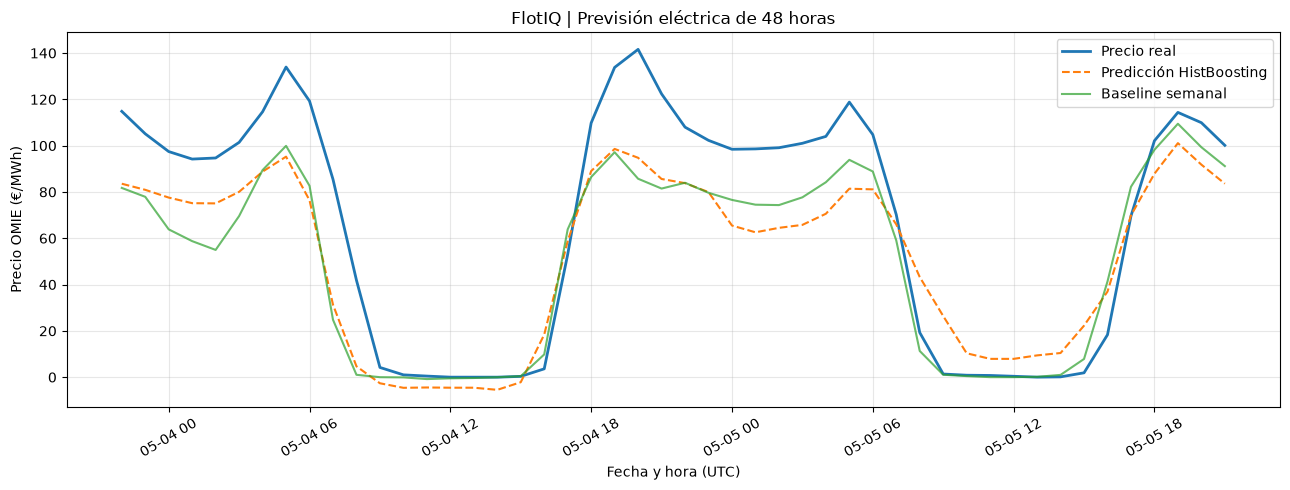

In [13]:

# FLOTIQ | PRIMERA PREVISIÓN OPERATIVA DE 48H
# =============================================

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Inicio de la última ventana de validación
inicio_prediccion = (
    test_start - pd.Timedelta(days=60)
)

# Solo entrenamos con información anterior
datos_entrenamiento = df[
    df["datetime_utc"] < inicio_prediccion
].copy()

# Las próximas 48 horas que queremos predecir
proximas_48h = df[
    (df["datetime_utc"] >= inicio_prediccion)
    & (
        df["datetime_utc"]
        < inicio_prediccion + pd.Timedelta(hours=48)
    )
].copy()

assert len(proximas_48h) == 48

# Los lags de 72h y 168h son conocidos
# antes de emitir toda esta previsión.
modelo_48h = clone(mejor_hgb)

modelo_48h.fit(
    datos_entrenamiento[FEATURES],
    datos_entrenamiento[TARGET]
)

proximas_48h["Prediccion_HistBoosting"] = (
    modelo_48h.predict(proximas_48h[FEATURES])
)

proximas_48h["Baseline_semanal"] = (
    proximas_48h["price_lag_168h"]
)

# Evaluar las 48 horas
mae_modelo = mean_absolute_error(
    proximas_48h[TARGET],
    proximas_48h["Prediccion_HistBoosting"]
)

mae_baseline = mean_absolute_error(
    proximas_48h[TARGET],
    proximas_48h["Baseline_semanal"]
)

print("FLOTIQ | PREVISIÓN DE 48 HORAS")
print("Inicio:", inicio_prediccion)
print("Horizonte:", len(proximas_48h), "horas")

print(
    f"MAE HistGradientBoosting: {mae_modelo:.2f} €/MWh"
)

print(
    f"MAE Baseline semanal:     {mae_baseline:.2f} €/MWh"
)

# Visualización
plt.figure(figsize=(13, 5))

plt.plot(
    proximas_48h["datetime_utc"],
    proximas_48h[TARGET],
    label="Precio real",
    linewidth=2
)

plt.plot(
    proximas_48h["datetime_utc"],
    proximas_48h["Prediccion_HistBoosting"],
    label="Predicción HistBoosting",
    linestyle="--"
)

plt.plot(
    proximas_48h["datetime_utc"],
    proximas_48h["Baseline_semanal"],
    label="Baseline semanal",
    alpha=0.7
)

plt.title("FlotIQ | Previsión eléctrica de 48 horas")
plt.xlabel("Fecha y hora (UTC)")
plt.ylabel("Precio OMIE (€/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [14]:

# FLOTIQ | 30 PREVISIONES DE 48 HORAS
# ============================================

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Trabajamos en la última ventana de validación,
# sin tocar los 90 días de test.
inicio_validacion = (
    test_start - pd.Timedelta(days=60)
)

fin_validacion = test_start

# Entrenamos SOLO con datos anteriores
# a la ventana de validación.
datos_train = df[
    df["datetime_utc"] < inicio_validacion
].copy()

modelo = clone(mejor_hgb)

modelo.fit(
    datos_train[FEATURES],
    datos_train[TARGET]
)

resultados_48h = []

# Cada origen genera 48 predicciones horarias.
for numero, origen in enumerate(
    pd.date_range(
        start=inicio_validacion,
        end=fin_validacion,
        freq="48h",
        inclusive="left"
    ),
    start=1
):

    bloque = df[
        (df["datetime_utc"] >= origen)
        & (
            df["datetime_utc"]
            < origen + pd.Timedelta(hours=48)
        )
    ].copy()

    assert len(bloque) == 48

    # Variables disponibles al emitir la previsión
    pred_ml = modelo.predict(
        bloque[FEATURES]
    )

    pred_baseline = bloque[
        "price_lag_168h"
    ].to_numpy()

    precio_real = bloque[TARGET]

    resultados_48h.append({
        "Prevision": numero,
        "Fecha": origen,
        "MAE_HistBoosting":
            mean_absolute_error(precio_real, pred_ml),
        "MAE_Baseline":
            mean_absolute_error(precio_real, pred_baseline),
    })

resultados_48h_df = pd.DataFrame(
    resultados_48h
)

resultados_48h_df["Ganador"] = np.where(
    resultados_48h_df["MAE_HistBoosting"]
    < resultados_48h_df["MAE_Baseline"],
    "HistGradientBoosting",
    "Baseline semanal"
)

print("FLOTIQ | EVALUACIÓN DE 48 HORAS")
print("Previsiones:", len(resultados_48h_df))

print("\nRESULTADOS POR PREVISIÓN")
display(resultados_48h_df.round(2))

print("\nRESULTADO GLOBAL")

print(
    "MAE medio HistBoosting:",
    round(
        resultados_48h_df["MAE_HistBoosting"].mean(),
        2
    ),
    "€/MWh"
)

print(
    "MAE medio Baseline:",
    round(
        resultados_48h_df["MAE_Baseline"].mean(),
        2
    ),
    "€/MWh"
)

print("\nPREVISIONES GANADAS POR CADA MODELO")
display(
    resultados_48h_df["Ganador"].value_counts()
)


FLOTIQ | EVALUACIÓN DE 48 HORAS
Previsiones: 30

RESULTADOS POR PREVISIÓN


C:\Users\dieve\AppData\Local\Temp\ipykernel_12160\3820542949.py:88: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(resultados_48h_df.round(2))


,Prevision,Fecha,MAE_HistBoosting,MAE_Baseline,Ganador
0,1,2026-05-03 22:00:00+00:00,20.98,18.19,Baseline semanal
1,2,2026-05-05 22:00:00+00:00,24.40,24.13,Baseline semanal
2,3,2026-05-07 22:00:00+00:00,17.08,8.82,Baseline semanal
3,4,2026-05-09 22:00:00+00:00,29.34,27.04,Baseline semanal
4,5,2026-05-11 22:00:00+00:00,18.32,18.43,HistGradientBoosting
5,6,2026-05-13 22:00:00+00:00,24.24,30.26,HistGradientBoosting
6,7,2026-05-15 22:00:00+00:00,8.75,20.67,HistGradientBoosting
7,8,2026-05-17 22:00:00+00:00,15.97,21.19,HistGradientBoosting
8,9,2026-05-19 22:00:00+00:00,10.66,7.80,Baseline semanal
9,10,2026-05-21 22:00:00+00:00,13.35,13.93,HistGradientBoosting



RESULTADO GLOBAL
MAE medio HistBoosting: 19.82 €/MWh
MAE medio Baseline: 21.37 €/MWh

PREVISIONES GANADAS POR CADA MODELO


Ganador
Baseline semanal        17
HistGradientBoosting    13
Name: count, dtype: int64

In [15]:

# FLOTIQ | ¿QUÉ MODELO ELIGE MEJOR LAS HORAS BARATAS?
# ==================================================

from sklearn.base import clone
import numpy as np
import pandas as pd

HORAS_BARATAS = 12

# Usamos la misma ventana de validación de 60 días
inicio_validacion = test_start - pd.Timedelta(days=60)
fin_validacion = test_start

datos_train = df[
    df["datetime_utc"] < inicio_validacion
].copy()

modelo_horas = clone(mejor_hgb)

modelo_horas.fit(
    datos_train[FEATURES],
    datos_train[TARGET]
)

resultados_recarga = []

for numero, origen in enumerate(
    pd.date_range(
        start=inicio_validacion,
        end=fin_validacion,
        freq="48h",
        inclusive="left"
    ),
    start=1
):

    bloque = df[
        (df["datetime_utc"] >= origen)
        & (
            df["datetime_utc"]
            < origen + pd.Timedelta(hours=48)
        )
    ].copy().sort_values("datetime_utc")

    assert len(bloque) == 48

    bloque["Prediccion_ML"] = modelo_horas.predict(
        bloque[FEATURES]
    )

    bloque["Prediccion_Baseline"] = (
        bloque["price_lag_168h"]
    )

    # Elegimos las 12 horas más baratas
    # según cada método.
    horas_ml = bloque.nsmallest(
        HORAS_BARATAS, "Prediccion_ML"
    )

    horas_baseline = bloque.nsmallest(
        HORAS_BARATAS, "Prediccion_Baseline"
    )

    # Escenario ideal: conocer el precio real
    # de todas las horas de antemano.
    horas_perfectas = bloque.nsmallest(
        HORAS_BARATAS, TARGET
    )

    resultados_recarga.append({
        "Prevision": numero,
        "Coste_ML": horas_ml[TARGET].mean(),
        "Coste_Baseline": horas_baseline[TARGET].mean(),
        "Coste_Perfecto": horas_perfectas[TARGET].mean()
    })

resultados_recarga_df = pd.DataFrame(
    resultados_recarga
)

print("FLOTIQ | SELECCIÓN DE HORAS BARATAS")
print("Previsiones:", len(resultados_recarga_df))
print("Horas seleccionadas por previsión:", HORAS_BARATAS)

print("\nCOSTE REAL MEDIO DE LA ENERGÍA SELECCIONADA")

resumen_costes = (
    resultados_recarga_df[
        ["Coste_ML", "Coste_Baseline", "Coste_Perfecto"]
    ]
    .mean()
    .round(2)
)

display(resumen_costes.to_frame("€/MWh"))

# Comparar en cuántas previsiones gana cada uno
victorias_ml = (
    resultados_recarga_df["Coste_ML"]
    < resultados_recarga_df["Coste_Baseline"]
).sum()

victorias_baseline = (
    resultados_recarga_df["Coste_Baseline"]
    < resultados_recarga_df["Coste_ML"]
).sum()

empates = (
    resultados_recarga_df["Coste_ML"]
    == resultados_recarga_df["Coste_Baseline"]
).sum()

print("\nPREVISIONES CON SELECCIÓN MÁS BARATA")
print("HistGradientBoosting:", victorias_ml)
print("Baseline semanal:", victorias_baseline)
print("Empates:", empates)

print("\nPRIMERAS 10 PREVISIONES")
display(
    resultados_recarga_df.head(10).round(2)
)


FLOTIQ | SELECCIÓN DE HORAS BARATAS
Previsiones: 30
Horas seleccionadas por previsión: 12

COSTE REAL MEDIO DE LA ENERGÍA SELECCIONADA


,€/MWh
Coste_ML,7.56
Coste_Baseline,8.15
Coste_Perfecto,5.64



PREVISIONES CON SELECCIÓN MÁS BARATA
HistGradientBoosting: 13
Baseline semanal: 12
Empates: 5

PRIMERAS 10 PREVISIONES


,Prevision,Coste_ML,Coste_Baseline,Coste_Perfecto
0,1,4.15,0.68,0.44
1,2,20.85,25.01,11.42
2,3,1.67,4.19,0.69
3,4,0.42,0.42,-0.09
4,5,1.88,3.45,0.28
5,6,0.10,-0.00,-0.00
6,7,0.05,-0.16,-0.34
7,8,2.80,0.16,0.04
8,9,-0.26,-0.27,-0.31
9,10,-1.04,-1.05,-1.05


In [16]:

# FLOTIQ | EVALUACIÓN ECONÓMICA EN 3 VENTANAS
# ================================================

from sklearn.base import clone
import pandas as pd
import numpy as np

HORAS_BARATAS = 12
DIAS_POR_FOLD = 60
NUM_FOLDS = 3

resultados_economicos = []

for fold in range(NUM_FOLDS):

    inicio = test_start - pd.Timedelta(
        days=(NUM_FOLDS - fold) * DIAS_POR_FOLD
    )

    fin = inicio + pd.Timedelta(
        days=DIAS_POR_FOLD
    )

    # Entrenar solamente con información anterior
    datos_train = df[
        df["datetime_utc"] < inicio
    ].copy()

    modelo = clone(mejor_hgb)

    modelo.fit(
        datos_train[FEATURES],
        datos_train[TARGET]
    )

    # Emitimos una previsión cada 48 horas
    for origen in pd.date_range(
        inicio,
        fin,
        freq="48h",
        inclusive="left"
    ):

        bloque = df[
            (df["datetime_utc"] >= origen)
            & (
                df["datetime_utc"] <
                origen + pd.Timedelta(hours=48)
            )
        ].copy()

        assert len(bloque) == 48

        bloque["ML"] = modelo.predict(
            bloque[FEATURES]
        )

        bloque["Baseline"] = (
            bloque["price_lag_168h"]
        )

        precio_ml = bloque.nsmallest(
            HORAS_BARATAS, "ML"
        )[TARGET].mean()

        precio_baseline = bloque.nsmallest(
            HORAS_BARATAS, "Baseline"
        )[TARGET].mean()

        precio_perfecto = bloque.nsmallest(
            HORAS_BARATAS, TARGET
        )[TARGET].mean()

        resultados_economicos.append({
            "Fold": fold + 1,
            "Origen": origen,
            "ML": precio_ml,
            "Baseline": precio_baseline,
            "Perfecto": precio_perfecto,
        })

economia_df = pd.DataFrame(
    resultados_economicos
)

print("FLOTIQ | EVALUACIÓN ECONÓMICA")
print("Previsiones:", len(economia_df))

print("\nPRECIO REAL MEDIO POR VENTANA (€/MWh)")
resumen_folds = (
    economia_df
    .groupby("Fold")[["ML", "Baseline", "Perfecto"]]
    .mean()
)

display(resumen_folds.round(2))

print("\nRESULTADO GLOBAL (€/MWh)")
display(
    economia_df[["ML", "Baseline", "Perfecto"]]
    .mean()
    .round(2)
    .to_frame("Precio medio")
)

print("\nVENTANAS GANADAS POR CADA MÉTODO")
print(
    np.where(
        resumen_folds["ML"] < resumen_folds["Baseline"],
        "HistGradientBoosting",
        "Baseline semanal"
    )
)


FLOTIQ | EVALUACIÓN ECONÓMICA
Previsiones: 90

PRECIO REAL MEDIO POR VENTANA (€/MWh)


,ML,Baseline,Perfecto
Fold,,,
1,25.57,27.59,20.84
2,6.72,8.28,4.99
3,7.56,8.15,5.64



RESULTADO GLOBAL (€/MWh)


,Precio medio
ML,13.29
Baseline,14.67
Perfecto,10.49



VENTANAS GANADAS POR CADA MÉTODO
['HistGradientBoosting' 'HistGradientBoosting' 'HistGradientBoosting']
